# 06 — Managerial Insights

## tl;dr

This notebook consolidates the analytical evidence into a business-facing format: **Finding → Operational implication → Possible managerial action**, with explicit limitations. It is designed to support an MBA report and presentation rather than introduce new model complexity.

## Context & Methods

The notebook reads the compact evidence tables created by Notebooks 03–05. Recommendations remain conditional: they identify where managers should differentiate planning or investigate further, not guaranteed outcomes or precise inventory policies.

In [1]:
from pathlib import Path
import sys
import warnings

warnings.filterwarnings("ignore", category=FutureWarning)
# Resolve the repository root dynamically so the notebook works from either
# the project root or the notebooks directory without a local absolute path.
candidate = Path.cwd().resolve()
PROJECT_ROOT = next(
    path for path in (candidate, *candidate.parents)
    if (path / "data").is_dir() and (path / "src").is_dir()
)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"
OUTPUT_DATA_DIR = PROJECT_ROOT / "outputs" / "processed_data"
FIGURE_DIR = PROJECT_ROOT / "reports" / "figures"
TABLE_DIR = PROJECT_ROOT / "reports" / "tables"
for directory in (PROCESSED_DATA_DIR, OUTPUT_DATA_DIR, FIGURE_DIR, TABLE_DIR):
    # Creating output folders is safe; raw source files are never modified.
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_SEED = 42

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from src.visualization import PROJECT_COLORS, save_figure, set_project_style

set_project_style()
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")

required_tables = [
    "store_operations_summary.csv", "family_operations_segments.csv",
    "promotion_operations_summary.csv", "peak_weekdays.csv", "peak_months.csv",
    "forecast_model_average.csv",
]
missing = [name for name in required_tables if not (TABLE_DIR / name).exists()]
if missing:
    raise FileNotFoundError(f"Run Notebooks 03–05 first. Missing tables: {missing}")

stores = pd.read_csv(TABLE_DIR / "store_operations_summary.csv")
families = pd.read_csv(TABLE_DIR / "family_operations_segments.csv")
promotions = pd.read_csv(TABLE_DIR / "promotion_operations_summary.csv")
weekdays = pd.read_csv(TABLE_DIR / "peak_weekdays.csv")
months = pd.read_csv(TABLE_DIR / "peak_months.csv")
models = pd.read_csv(TABLE_DIR / "forecast_model_average.csv")

## Results

### 1. Executive evidence snapshot

**Why this step is needed:** Decision-makers need a compact view of the strongest network, category, timing, variability, and forecasting signals before reading detailed recommendations.

In [3]:
top_store = stores.nlargest(1, "average_daily_sales").iloc[0]
comparable_stores = stores.loc[stores["comparable_store"].astype(bool)]
volatile_store = comparable_stores.nlargest(1, "demand_cv").iloc[0]
top_family = families.nlargest(1, "total_sales").iloc[0]
volatile_family = families.nlargest(1, "cv").iloc[0]
peak_day = weekdays.nlargest(1, "mean").iloc[0]
peak_month = months.nlargest(1, "mean").iloc[0]
best_model = models.nsmallest(1, "MAE").iloc[0]

snapshot = pd.DataFrame(
    [
        ("Highest average-demand store", f"Store {int(top_store.store_nbr)}", top_store.average_daily_sales),
        ("Most variable comparable store", f"Store {int(volatile_store.store_nbr)}", volatile_store.demand_cv),
        ("Largest product family", top_family.family, top_family.total_sales),
        ("Most variable family", volatile_family.family, volatile_family.cv),
        ("Peak average weekday", peak_day.weekday, peak_day["mean"]),
        ("Peak average month", f"Month {int(peak_month.month)}", peak_month["mean"]),
        ("Lowest average-MAE model", best_model.model, best_model.MAE),
    ],
    columns=["indicator", "result", "value"],
)
display(snapshot)

,indicator,result,value
0,Highest average-demand store,Store 44,"36,869.093"
1,Most variable comparable store,Store 25,0.702
2,Largest product family,GROCERY I,"343,462,734.886"
3,Most variable family,BOOKS,3.392
4,Peak average weekday,Sunday,"825,218.122"
5,Peak average month,Month 12,"808,565.340"
6,Lowest average-MAE model,Random Forest (rolling 1-day),414.408


### 2. Finding → implication → action register

**Why this step is needed:** This structure prevents recommendations from becoming generic: every action is tied to observed evidence and accompanied by the limitation that constrains the claim.

In [4]:
high_stable = families.loc[families["segment"].eq("High demand / Stable")].nlargest(3, "total_sales")["family"].tolist()
high_volatile = families.loc[families["segment"].eq("High demand / Volatile")].nlargest(3, "total_sales")["family"].tolist()
top_promo = promotions.loc[promotions["promoted_observations"].ge(100)].nlargest(3, "observed_ratio")["family"].tolist()

insights = pd.DataFrame(
    [
        {
            "Finding": f"High-demand/stable families include {', '.join(high_stable) or 'none under the median rule'}.",
            "Operational implication": "Large, relatively predictable flows can anchor routine capacity and replenishment planning.",
            "Possible managerial action": "Use regular review cycles and supplier schedules, then monitor exceptions rather than treating every day as equally uncertain.",
            "Limitation": "Inventory policy still requires lead times, stock, costs, and service targets.",
        },
        {
            "Finding": f"High-demand/volatile families include {', '.join(high_volatile) or 'none under the median rule'}.",
            "Operational implication": "These categories combine commercial importance with planning uncertainty.",
            "Possible managerial action": "Prioritize shorter planning cycles, scenario ranges, and closer supplier coordination for these families.",
            "Limitation": "CV is a relative historical measure and does not identify the cause of volatility.",
        },
        {
            "Finding": f"Store {int(volatile_store.store_nbr)} has the highest daily-demand CV ({volatile_store.demand_cv:.3f}) among stores meeting the 90% coverage rule.",
            "Operational implication": "Uniform store rules may leave volatile locations under- or over-prepared.",
            "Possible managerial action": "Use store-specific staffing and receiving flexibility, and investigate local calendar or assortment drivers.",
            "Limitation": "CV remains descriptive; sales mix and local operating conditions may explain part of the difference.",
        },
        {
            "Finding": f"Average network demand peaks on {peak_day.weekday} and in month {int(peak_month.month)}.",
            "Operational implication": "Recurring peaks can strain labor, shelf replenishment, checkout, receiving, and supplier capacity.",
            "Possible managerial action": "Review rosters, delivery windows, and replenishment frequency ahead of these recurring periods.",
            "Limitation": "Averages can mask store- and family-specific peak timing.",
        },
        {
            "Finding": f"Strong promotion-associated ratios appear for {', '.join(top_promo)} among adequately represented families.",
            "Operational implication": "Promotion response appears heterogeneous and may create category-specific capacity pressure.",
            "Possible managerial action": "Coordinate promotions with replenishment and staffing; test incremental lift with stronger causal designs.",
            "Limitation": "The descriptive ratio is not causal and may reflect promotion targeting or seasonality.",
        },
        {
            "Finding": f"{best_model.model} has the lowest average validation MAE ({best_model.MAE:,.2f}) for the selected series.",
            "Operational implication": "Forecasting can improve short-horizon visibility for selected demand series, but value varies by series.",
            "Possible managerial action": "Pilot forecasts alongside a seasonal-naive baseline and monitor error by store-family before wider use.",
            "Limitation": "Validation covers selected series and one historical period; it does not prove inventory savings.",
        },
    ]
)
display(insights)
insights.to_csv(TABLE_DIR / "managerial_insights.csv", index=False)

,Finding,Operational implication,Possible managerial action,Limitation
0,"High-demand/stable families include GROCERY I,...","Large, relatively predictable flows can anchor...",Use regular review cycles and supplier schedul...,"Inventory policy still requires lead times, st..."
1,"High-demand/volatile families include PRODUCE,...",These categories combine commercial importance...,"Prioritize shorter planning cycles, scenario r...",CV is a relative historical measure and does n...
2,Store 25 has the highest daily-demand CV (0.70...,Uniform store rules may leave volatile locatio...,Use store-specific staffing and receiving flex...,CV remains descriptive; sales mix and local op...
3,Average network demand peaks on Sunday and in ...,"Recurring peaks can strain labor, shelf replen...","Review rosters, delivery windows, and replenis...",Averages can mask store- and family-specific p...
4,Strong promotion-associated ratios appear for ...,Promotion response appears heterogeneous and m...,Coordinate promotions with replenishment and s...,The descriptive ratio is not causal and may re...
5,Random Forest (rolling 1-day) has the lowest a...,Forecasting can improve short-horizon visibili...,Pilot forecasts alongside a seasonal-naive bas...,Validation covers selected series and one hist...


### 3. Portfolio priorities for presentation

**Why this step is needed:** A single portfolio chart communicates how many categories require routine versus flexible planning and can be reused directly in the MBA presentation.

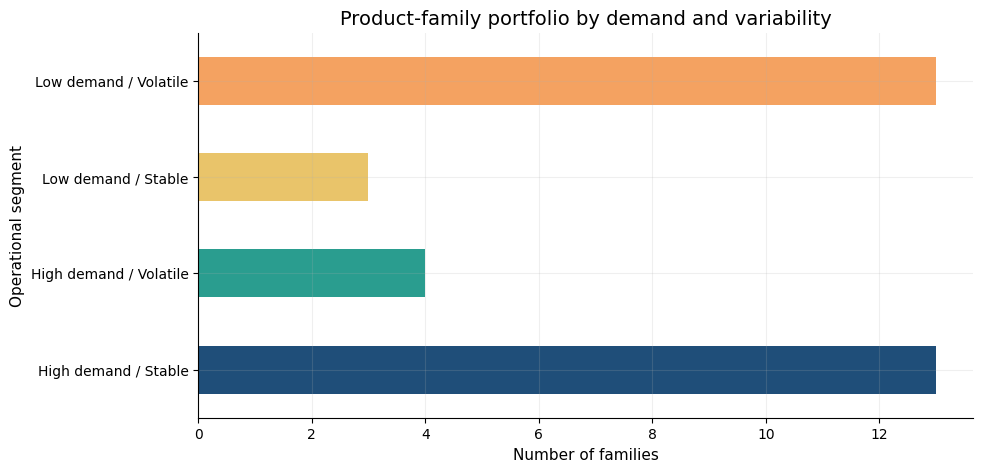

In [5]:
segment_counts = families["segment"].value_counts().reindex(
    ["High demand / Stable", "High demand / Volatile", "Low demand / Stable", "Low demand / Volatile"], fill_value=0
)
fig, ax = plt.subplots(figsize=(10, 5))
segment_counts.plot(kind="barh", ax=ax, color=PROJECT_COLORS)
ax.set(title="Product-family portfolio by demand and variability", xlabel="Number of families", ylabel="Operational segment")
save_figure(fig, FIGURE_DIR, "managerial_01_portfolio_segments.png")
plt.show()

## Takeaways

In [6]:
display(Markdown(f'''
1. **Differentiate the portfolio.** Stable high-demand families support standardized routines; volatile high-demand families merit closer review and flexibility.
2. **Plan locally.** Among stores with adequate lifecycle coverage, Store {int(volatile_store.store_nbr)} illustrates why a single network-wide variability assumption is insufficient. Later-opening stores should be analyzed separately.
3. **Prepare for recurring peaks.** {peak_day.weekday} and month {int(peak_month.month)} are network-level signals for labor, receiving, replenishment, and supplier coordination reviews.
4. **Treat promotion evidence carefully.** Use observed differences to prioritize tests and operational coordination, not to claim causal lift.
5. **Use forecasting as support.** Retain transparent baselines, monitor by series, and connect forecasts to actual planning decisions before expanding complexity.
6. **Request missing operational data.** Stock levels, stockouts, lead times, costs, margins, order quantities, and service targets are needed for inventory-policy or financial-impact claims.
'''))


1. **Differentiate the portfolio.** Stable high-demand families support standardized routines; volatile high-demand families merit closer review and flexibility.
2. **Plan locally.** Among stores with adequate lifecycle coverage, Store 25 illustrates why a single network-wide variability assumption is insufficient. Later-opening stores should be analyzed separately.
3. **Prepare for recurring peaks.** Sunday and month 12 are network-level signals for labor, receiving, replenishment, and supplier coordination reviews.
4. **Treat promotion evidence carefully.** Use observed differences to prioritize tests and operational coordination, not to claim causal lift.
5. **Use forecasting as support.** Retain transparent baselines, monitor by series, and connect forecasts to actual planning decisions before expanding complexity.
6. **Request missing operational data.** Stock levels, stockouts, lead times, costs, margins, order quantities, and service targets are needed for inventory-policy or financial-impact claims.
